In [2]:
import pandas as pd 
import numpy as np 

import matplotlib.pyplot as plt

In [4]:
finance = pd.read_csv("Day7_Finance_Transactions.csv")
finance.head()


,transaction_id,transaction_date,department,vendor,budget_amount,actual_amount,approval_status,payment_method
0,FIN1001,2026-10-01,Marketing,Northstar Services,19795.0,19942.03,Rejected,UPI
1,FIN1002,2026-10-19,Finance,Northstar Services,4860.0,6101.82,Approved,Bank Transfer
2,FIN1003,2026-10-30,Finance,Northstar Services,42158.0,43968.56,Approved,UPI
3,FIN1004,2026-10-02,Marketing,Apex Supplies,48732.0,47536.42,Approved,Bank Transfer
4,FIN1005,2026-10-21,Marketing,Apex Supplies,15284.0,10518.57,Approved,UPI


Check the shape of the data: 


In [5]:
finance.shape

(81, 8)

In [6]:
finance.info()

<class 'pandas.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    81 non-null     str    
 1   transaction_date  81 non-null     str    
 2   department        81 non-null     str    
 3   vendor            81 non-null     str    
 4   budget_amount     81 non-null     float64
 5   actual_amount     79 non-null     float64
 6   approval_status   81 non-null     str    
 7   payment_method    81 non-null     str    
dtypes: float64(2), str(6)
memory usage: 5.2 KB


1. Which columns are numeric and which are categorical?
- 2 are numeric columns: budget and actual amount
- others are categorical columns: transaction_id, transaction_date, department, vendor, approval_status, payment_method
2. Why transaction_id matter ? 
- transaction_id is a unique identifier for each transaction. It helps in tracking and referencing specific transactions, ensuring data integrity and preventing duplication.



In [7]:
finance_copy = finance.copy()

In [8]:
print("Exact duplicates rows: ",finance.duplicated().sum())

Exact duplicates rows:  1


In [9]:
fin_clean = finance_copy.drop_duplicates()

In [11]:
print("Rows after deduplication: ",len(fin_clean))

Rows after deduplication:  80


In [12]:
print("Missing actual amount: ",
      fin_clean['actual_amount'].isna().sum())

Missing actual amount:  2


In [14]:
analysis_data = fin_clean.dropna(subset=['actual_amount'])

In [16]:
analysis_data.describe(include='all')

,transaction_id,transaction_date,department,vendor,budget_amount,actual_amount,approval_status,payment_method
count,78,78,78,78,78.000000,78.000000,78,78
unique,78,28,5,6,NaN,NaN,3,4
top,FIN1001,2026-10-16,Marketing,Northstar Services,NaN,NaN,Approved,Bank Transfer
freq,1,6,20,18,NaN,NaN,52,24
mean,NaN,NaN,NaN,NaN,25198.538462,25975.617051,NaN,NaN
std,NaN,NaN,NaN,NaN,14941.156382,20584.417761,NaN,NaN
min,NaN,NaN,NaN,NaN,4161.000000,1957.140000,NaN,NaN
25%,NaN,NaN,NaN,NaN,11263.000000,11262.840000,NaN,NaN
50%,NaN,NaN,NaN,NaN,23287.500000,22375.750000,NaN,NaN
75%,NaN,NaN,NaN,NaN,39883.250000,36089.342500,NaN,NaN


In [18]:
mean_actual = analysis_data['actual_amount'].mean()
mean_actual

np.float64(25975.61705128205)

In [20]:
median_actual = analysis_data['actual_amount'].median()
median_actual

np.float64(22375.75)

In [21]:
print(f"Mean: {mean_actual:.2f}")

Mean: 25975.62


In [22]:
print("Median: ",round(median_actual,2))

Median:  22375.75


Here Mean > Median. So, it suggests that few large values may be pulling the mean / average upward. This is the clue about the skewness of the data. 

In [28]:
round(analysis_data['actual_amount'].skew(),3)

np.float64(1.971)

In [29]:
round(analysis_data['actual_amount'].kurt(),3)

np.float64(6.253)

Histogram

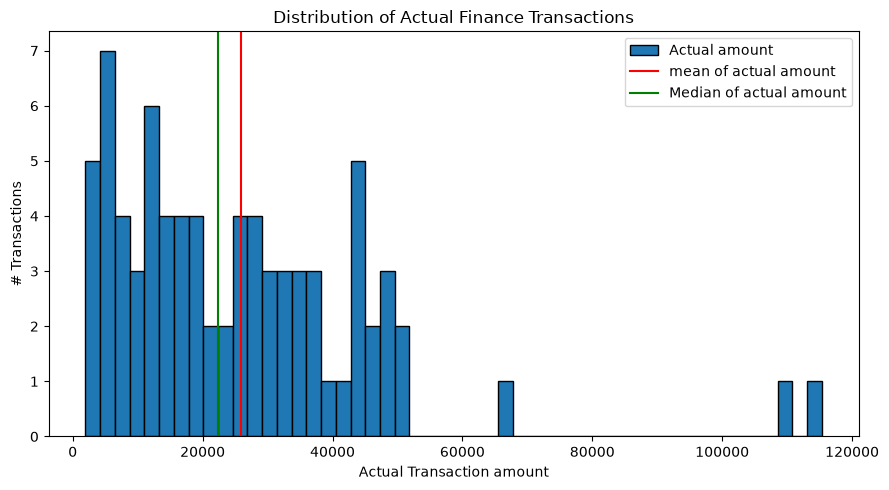

In [ ]:
plt.figure(figsize = (9,5))

plt.hist(analysis_data['actual_amount'],bins=50,edgecolor='k',label="Actual amount")
plt.axvline(mean_actual,color = 'r',label = "mean of actual amount")
plt.axvline(median_actual,color='green',label = "Median of actual amount")
plt.xlabel("Actual Transaction amount")
plt.ylabel("# Transactions")
plt.legend()
plt.title("Distribution of Actual Finance Transactions")

plt.tight_layout()
plt.show()

- Q1 = 25% of the data, Q2 = 50% of the data, Q3 = 75% of the data.
- IQR = Q3 - Q1

In [41]:
q1 = analysis_data['actual_amount'].quantile(0.25)
q2 = analysis_data['actual_amount'].quantile(0.50)
q3 = analysis_data['actual_amount'].quantile(0.75)

In [42]:
IQR = q3 - q1 
lower_fence  = q1 - 1.5 * IQR 
upper_fence = q3 + 1.5 * IQR

In [44]:
print(q1,q2,q3,IQR,lower_fence,upper_fence)

11262.84 22375.75 36089.3425 24826.5025 -25976.913749999996 73329.09625


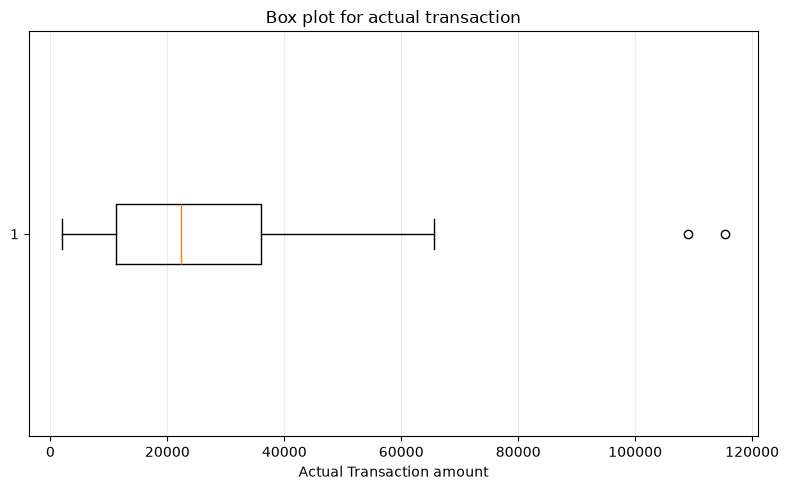

In [48]:
plt.figure(figsize=(8,5))
plt.boxplot(analysis_data['actual_amount'],orientation="horizontal")
plt.xlabel("Actual Transaction amount")
plt.title("Box plot for actual transaction")
plt.grid(axis='x',alpha=0.25)
plt.tight_layout()
plt.show()

## Flag potential outliers at transaction level : 

In [56]:
analysis_data['iqr_outlier'] = (
    (analysis_data['actual_amount'] < lower_fence)
    |
    (analysis_data['actual_amount'] > upper_fence)
)

In [57]:
outliers = analysis_data[analysis_data['iqr_outlier']].copy()

In [58]:
print(outliers[['transaction_id','department','vendor','actual_amount']])

   transaction_id department                  vendor  actual_amount
7         FIN1008    Finance  PeopleFirst Consulting       115343.2
23        FIN1024    Finance  PeopleFirst Consulting       109041.6


In [60]:
print("Potential outlier count : ",len(outliers))

Potential outlier count :  2


Department wise spending analysis :

In [64]:
dept_summary = (analysis_data.groupby('department')['actual_amount'].agg(count_actual = 'count',
                                                                         mean_actual = 'mean',
                                                                         median_actual = 'median',
                                                                         min_actual= 'min',
                                                                         max_actual = 'max').round(2))

In [65]:
dept_summary

,count_actual,mean_actual,median_actual,min_actual,max_actual
department,,,,,
Finance,20,32142.86,21101.91,3747.32,115343.20
HR,14,20182.20,15685.54,1957.14,44357.04
IT,15,27252.59,25456.56,5210.50,50609.87
Marketing,20,22108.52,17277.26,4597.42,48548.69
Operations,9,27747.87,28226.64,16191.63,45377.39


In [71]:
def flag_iqr(group): 
    q1 = group['actual_amount'].quantile(0.25)
    q2 = group['actual_amount'].quantile(0.5)
    q3 = group['actual_amount'].quantile(0.75)

    iqr = q3 -q1 
    low,high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    group = group.copy()
    group['dept_iqr_outliers'] = ((group['actual_amount']<low) | 
                                (group['actual_amount'] > high))
    return group 



In [73]:
dept_checked = analysis_data.groupby('department',group_keys = False).apply(flag_iqr)
display(dept_checked[dept_checked['dept_iqr_outliers']])

,transaction_id,transaction_date,vendor,budget_amount,actual_amount,approval_status,payment_method,iqr_outlier,dept_iqr_outliers
7,FIN1008,2026-10-06,PeopleFirst Consulting,41194.0,115343.20,Approved,Bank Transfer,True,True
23,FIN1024,2026-10-11,PeopleFirst Consulting,45434.0,109041.60,Pending,Cheque,True,True
77,FIN1078,2026-10-12,Metro Logistics,44397.0,45377.39,Pending,Corporate Card,False,True


### Z-Score method:
The z-score method is a statistical technique used to identify outliers in a dataset. It measures how many standard deviations a data point is from the mean of the dataset. A z-score is calculated using the formula:
```
z = (X - μ) / σ
```
Where:
- X is the data point
- μ is the mean of the dataset
- σ is the standard deviation of the dataset
A z-score greater than a certain threshold (commonly 2 or 3) indicates that the data point is an outlier. This method is effective for normally distributed data and helps in identifying extreme values that deviate significantly from the mean.

In [75]:
std_actual = analysis_data['actual_amount'].std()

analysis_data['z_score'] = (analysis_data['actual_amount'] - mean_actual) / std_actual
z_outliers = analysis_data[analysis_data['z_score'].abs() > 3]
print(z_outliers[['transaction_id','actual_amount','z_score']])

   transaction_id  actual_amount   z_score
7         FIN1008       115343.2  4.341516
23        FIN1024       109041.6  4.035382


Exception Register: 


In [76]:
outliers.columns

Index(['transaction_id', 'transaction_date', 'department', 'vendor',
       'budget_amount', 'actual_amount', 'approval_status', 'payment_method',
       'iqr_outlier'],
      dtype='str')

In [77]:
exception_register = outliers[['transaction_id', 'transaction_date', 'department', 'vendor',
       'budget_amount', 'actual_amount', 'approval_status']].copy()

In [ ]:
exception_register['exception_reason'] = "Actual amount is outside the IQR bound/fences"
exception_register['review_status'] = 'Pending Review'
exception_register.to_excel("Day7_exception_register.xlsx")